### 1. Chuẩn bị thư viện

In [1]:
%pip install "scikit-learn>=1.2" pandas numpy joblib ipython

import json
import platform
import time
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

print('Python:', platform.python_version())
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Python: 3.14.7
pandas: 3.1.1
scikit-learn: 1.9.1


### 2. Cấu hình thí nghiệm và đường dẫn

In [2]:
EXPERIMENT = {
    'id': 'E01',
    'family': 'DT',
    'variant': 'baseline',
    'hypothesis': 'Cây không giới hạn là mốc so sánh, có thể overfit.',
    'params': {},
}

TRAIN_PATH = Path(r'C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\splitted data\train.csv.gz')
VALID_PATH = Path(r'C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\splitted data\validation.csv.gz')
TARGET_COLUMN = 'Attack_type'
DROP_COLUMNS = ['group_id', 'Unnamed: 0']

RANDOM_STATE = 42
N_SPLITS = 3
REPORTS_ROOT = Path('reports')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = REPORTS_ROOT / f"{EXPERIMENT['id']}_DT_baseline" / RUN_ID

METRIC_NAMES = [
    'accuracy', 'macro_f1', 'weighted_f1', 'macro_precision', 'macro_recall'
]

print('Thư mục làm việc:', Path.cwd())
print('Train:', TRAIN_PATH.resolve())
print('Valid:', VALID_PATH.resolve())
print('Kết quả sẽ lưu tại:', RUN_DIR.resolve())


Thư mục làm việc: c:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\baseline\DT_baseline
Train: C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\splitted data\train.csv.gz
Valid: C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\splitted data\validation.csv.gz
Kết quả sẽ lưu tại: C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\final_IoT\sample_project\result\baseline\DT_baseline\reports\E01_DT_baseline\20261112T164216417387Z


### 3. Đọc và kiểm tra Train

In [3]:
def extract_xy(frame, *, feature_order=None, numeric_columns=None):
    if frame.empty:
        raise ValueError('File dữ liệu không có dòng nào.')
    if TARGET_COLUMN not in frame.columns:
        raise ValueError(
            f'Không có cột nhãn {TARGET_COLUMN!r}. '
            f'Các cột hiện có: {frame.columns.tolist()}'
        )

    raw_y = frame[TARGET_COLUMN]
    if raw_y.isna().any() or raw_y.astype(str).str.strip().eq('').any():
        raise ValueError('Cột nhãn có giá trị thiếu/rỗng; cần kiểm tra file đầu vào.')
    y = raw_y.astype(str).reset_index(drop=True)
    X = frame.drop(columns=[TARGET_COLUMN] + DROP_COLUMNS, errors='ignore').copy()
    X = X.reset_index(drop=True)
    if X.shape[1] == 0:
        raise ValueError('Không còn đặc trưng đầu vào sau khi bỏ các cột chỉ định.')

    if feature_order is not None:
        missing = sorted(set(feature_order) - set(X.columns))
        extra = sorted(set(X.columns) - set(feature_order))
        if missing or extra:
            raise ValueError(
                f'Train/Valid khác bộ đặc trưng. Thiếu ở Valid: {missing}; '
                f'Thừa ở Valid: {extra}'
            )
        X = X.loc[:, feature_order]

    if numeric_columns is None:
        numeric_columns = X.select_dtypes(include=[np.number]).columns.tolist()
    for col in numeric_columns:
        # Lỗi kiểu dữ liệu ở Valid phải được báo, không âm thầm đổi thành NaN.
        X[col] = pd.to_numeric(X[col], errors='raise').astype(float)
    X[numeric_columns] = X[numeric_columns].replace([np.inf, -np.inf], np.nan)

    categorical_columns = [col for col in X.columns if col not in numeric_columns]
    for col in categorical_columns:
        X[col] = X[col].map(lambda value: str(value) if pd.notna(value) else np.nan)
    return X, y, numeric_columns, categorical_columns


if TRAIN_PATH.resolve() == VALID_PATH.resolve():
    raise ValueError('Train và Valid phải là hai file đã chia riêng.')
if not TRAIN_PATH.is_file():
    raise FileNotFoundError(f'Không tìm thấy Train: {TRAIN_PATH.resolve()}')

train_df = pd.read_csv(TRAIN_PATH)
X_train, y_train, NUMERIC_COLUMNS, CATEGORICAL_COLUMNS = extract_xy(train_df)
FEATURE_COLUMNS = X_train.columns.tolist()
LABELS = sorted(y_train.unique().tolist())
class_counts = y_train.value_counts().sort_index()

if len(LABELS) < 2:
    raise ValueError('Train cần có ít nhất 2 lớp để phân loại.')
if class_counts.min() < N_SPLITS:
    raise ValueError(
        f'Mỗi lớp cần ít nhất {N_SPLITS} mẫu để chạy StratifiedKFold 3 folds. '
        f'Các lớp chưa đủ: {class_counts[class_counts < N_SPLITS].to_dict()}'
    )

print(f'Train: {len(X_train):,} dòng × {X_train.shape[1]} đặc trưng')
print(f'Số lớp: {len(LABELS)}')
print(f'Cột số: {len(NUMERIC_COLUMNS)}; cột phân loại: {len(CATEGORICAL_COLUMNS)}')
print('Cột đã loại:', [col for col in DROP_COLUMNS if col in train_df.columns])
display(class_counts.rename('n_train').to_frame())
del train_df


Train: 82,536 dòng × 82 đặc trưng
Số lớp: 12
Cột số: 80; cột phân loại: 2
Cột đã loại: []


,n_train
Attack_type,
ARP_poisioning,5334
DDOS_Slowloris,373
DOS_SYN_Hping,63062
MQTT_Publish,2899
Metasploit_Brute_Force_SSH,25
NMAP_FIN_SCAN,20
NMAP_OS_DETECTION,1400
NMAP_TCP_scan,701
NMAP_UDP_SCAN,1807


### 4. Pipeline baseline và hàm tính 5 chỉ số

In [4]:
transformers = []
if NUMERIC_COLUMNS:
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
    ])
    transformers.append(('numeric', numeric_pipeline, NUMERIC_COLUMNS))

if CATEGORICAL_COLUMNS:
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(
            strategy='constant', fill_value='__MISSING__', keep_empty_features=True
        )),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=True)),
    ])
    transformers.append(('categorical', categorical_pipeline, CATEGORICAL_COLUMNS))

preprocessor = ColumnTransformer(transformers=transformers, remainder='drop')
# Seed cố định là thiết lập tái lập, EXPERIMENT['params'] vẫn giữ nguyên {}.
model_params = {'random_state': RANDOM_STATE, **EXPERIMENT['params']}
base_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', DecisionTreeClassifier(**model_params)),
])


def compute_metrics(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(
            y_true, y_pred, labels=LABELS, average='macro', zero_division=0
        )),
        'weighted_f1': float(f1_score(
            y_true, y_pred, labels=LABELS, average='weighted', zero_division=0
        )),
        'macro_precision': float(precision_score(
            y_true, y_pred, labels=LABELS, average='macro', zero_division=0
        )),
        'macro_recall': float(recall_score(
            y_true, y_pred, labels=LABELS, average='macro', zero_division=0
        )),
    }


print('Tham số thực tế của cây:')
print(json.dumps(base_pipeline.named_steps['model'].get_params(), indent=2))


Tham số thực tế của cây:
{
  "ccp_alpha": 0.0,
  "class_weight": null,
  "criterion": "gini",
  "max_depth": null,
  "max_features": null,
  "max_leaf_nodes": null,
  "min_impurity_decrease": 0.0,
  "min_samples_leaf": 1,
  "min_samples_split": 2,
  "min_weight_fraction_leaf": 0.0,
  "monotonic_cst": null,
  "random_state": 42,
  "splitter": "best"
}


### 5. Chạy 3-fold CV chỉ trên Train

In [5]:
# RUN_DIR.mkdir(parents=True, exist_ok=False)
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
fold_records = []
oof_predictions = np.empty(len(y_train), dtype=object)
fold_assignment = np.zeros(len(y_train), dtype=int)
oof_coverage = np.zeros(len(y_train), dtype=int)

for fold, (fit_index, cv_index) in enumerate(cv.split(X_train, y_train), start=1):
    X_fit, X_cv = X_train.iloc[fit_index], X_train.iloc[cv_index]
    y_fit, y_cv = y_train.iloc[fit_index], y_train.iloc[cv_index]

    fold_pipeline = clone(base_pipeline)
    started = time.perf_counter()
    fold_pipeline.fit(X_fit, y_fit)
    fit_seconds = time.perf_counter() - started

    started = time.perf_counter()
    cv_prediction = fold_pipeline.predict(X_cv)
    predict_seconds = time.perf_counter() - started
    train_prediction = fold_pipeline.predict(X_fit)

    cv_scores = compute_metrics(y_cv, cv_prediction)
    train_scores = compute_metrics(y_fit, train_prediction)
    fitted_tree = fold_pipeline.named_steps['model']
    record = {
        'experiment_id': EXPERIMENT['id'],
        'fold': fold,
        'n_fit': len(fit_index),
        'n_cv': len(cv_index),
        **cv_scores,
        **{f'train_{name}': value for name, value in train_scores.items()},
        'tree_depth': fitted_tree.get_depth(),
        'n_leaves': fitted_tree.get_n_leaves(),
        'fit_seconds': fit_seconds,
        'predict_seconds': predict_seconds,
    }
    fold_records.append(record)
    oof_predictions[cv_index] = cv_prediction
    fold_assignment[cv_index] = fold
    oof_coverage[cv_index] += 1

    RUN_DIR.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(fold_records).to_csv(
        RUN_DIR / 'cv_fold_results.csv',
        index=False,
        encoding='utf-8-sig',
    )
    print(f'Fold {fold}/{N_SPLITS} | học: {len(fit_index):,} | CV: {len(cv_index):,}')
    display(pd.DataFrame([cv_scores, train_scores], index=['cv_validation', 'train_fit']).round(6))

if not np.all(oof_coverage == 1):
    raise RuntimeError('Mỗi mẫu Train phải được dự đoán CV đúng một lần.')

cv_results = pd.DataFrame(fold_records)
pd.DataFrame({
    'row_position': np.arange(len(y_train)),
    'fold': fold_assignment,
    'y_true': y_train.to_numpy(),
    'y_pred': oof_predictions,
}).to_csv(RUN_DIR / 'cv_oof_predictions.csv', index=False, encoding='utf-8-sig')

print('Bảng điểm CV của cả 3 lượt:')
display(cv_results[['fold', 'n_fit', 'n_cv'] + METRIC_NAMES].round(6))


Fold 1/3 | học: 55,024 | CV: 27,512


,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
cv_validation,0.997092,0.941239,0.997101,0.950772,0.94368
train_fit,1.000000,1.000000,1.000000,1.000000,1.00000


Fold 2/3 | học: 55,024 | CV: 27,512


,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
cv_validation,0.996801,0.939154,0.996816,0.94758,0.943734
train_fit,1.000000,1.000000,1.000000,1.00000,1.000000


Fold 3/3 | học: 55,024 | CV: 27,512


,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
cv_validation,0.997238,0.955182,0.997254,0.940047,0.980684
train_fit,1.000000,1.000000,1.000000,1.000000,1.000000


Bảng điểm CV của cả 3 lượt:


,fold,n_fit,n_cv,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
0,1,55024,27512,0.997092,0.941239,0.997101,0.950772,0.943680
1,2,55024,27512,0.996801,0.939154,0.996816,0.947580,0.943734
2,3,55024,27512,0.997238,0.955182,0.997254,0.940047,0.980684


### 6. Tổng hợp CV và xem chênh lệch Train-CV

In [6]:
cv_summary = pd.DataFrame({
    'metric': METRIC_NAMES,
    'cv_mean': [cv_results[name].mean() for name in METRIC_NAMES],
    'cv_std': [cv_results[name].std(ddof=1) for name in METRIC_NAMES],
    'train_mean': [cv_results[f'train_{name}'].mean() for name in METRIC_NAMES],
})
cv_summary['train_cv_gap'] = cv_summary['train_mean'] - cv_summary['cv_mean']
cv_summary.to_csv(RUN_DIR / 'cv_summary.csv', index=False, encoding='utf-8-sig')
display(cv_summary.round(6))

for row in cv_summary.itertuples(index=False):
    print(f'{row.metric:16s}: {row.cv_mean:.6f} ± {row.cv_std:.6f}')


,metric,cv_mean,cv_std,train_mean,train_cv_gap
0,accuracy,0.997044,0.000222,1.0,0.002956
1,macro_f1,0.945191,0.008714,1.0,0.054809
2,weighted_f1,0.997057,0.000222,1.0,0.002943
3,macro_precision,0.946133,0.005507,1.0,0.053867
4,macro_recall,0.956033,0.021349,1.0,0.043967


accuracy        : 0.997044 ± 0.000222
macro_f1        : 0.945191 ± 0.008714
weighted_f1     : 0.997057 ± 0.000222
macro_precision : 0.946133 ± 0.005507
macro_recall    : 0.956033 ± 0.021349


### 7. Học lại trên toàn bộ Train

In [7]:
final_pipeline = clone(base_pipeline)
started = time.perf_counter()
final_pipeline.fit(X_train, y_train)
final_fit_seconds = time.perf_counter() - started
full_train_scores = compute_metrics(y_train, final_pipeline.predict(X_train))

final_tree = final_pipeline.named_steps['model']
print(f'Đã học lại trên {len(X_train):,} mẫu Train.')
print(f'Thời gian học: {final_fit_seconds:.3f} giây')
print(f'Độ sâu cây: {final_tree.get_depth()}; số lá: {final_tree.get_n_leaves()}')
display(pd.DataFrame([full_train_scores], index=['full_train']).round(6))


Đã học lại trên 82,536 mẫu Train.
Thời gian học: 2.397 giây
Độ sâu cây: 20; số lá: 219


,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
full_train,1.0,1.0,1.0,1.0,1.0


### 8. Đọc Valid và đánh giá lần cuối

In [8]:
if not VALID_PATH.is_file():
    raise FileNotFoundError(f'Không tìm thấy Valid: {VALID_PATH.resolve()}')

valid_df = pd.read_csv(VALID_PATH)
X_valid, y_valid, _, _ = extract_xy(
    valid_df, feature_order=FEATURE_COLUMNS, numeric_columns=NUMERIC_COLUMNS
)
unknown_labels = sorted(set(y_valid.unique()) - set(LABELS))
if unknown_labels:
    raise ValueError(f'Valid có nhãn chưa xuất hiện trong Train: {unknown_labels}')

absent_labels = sorted(set(LABELS) - set(y_valid.unique()))
if absent_labels:
    print('Nhãn Train không có mẫu trong Valid:', absent_labels)
    print('Các điểm macro vẫn được tính trên toàn bộ danh sách LABELS của Train.')

started = time.perf_counter()
valid_prediction = final_pipeline.predict(X_valid)
final_predict_seconds = time.perf_counter() - started
valid_scores = compute_metrics(y_valid, valid_prediction)

final_valid_results = pd.DataFrame([{
    'experiment_id': EXPERIMENT['id'],
    'family': EXPERIMENT['family'],
    'variant': EXPERIMENT['variant'],
    'n_train': len(X_train),
    'n_valid': len(X_valid),
    **valid_scores,
    **{f'full_train_{name}': value for name, value in full_train_scores.items()},
    'tree_depth': final_tree.get_depth(),
    'n_leaves': final_tree.get_n_leaves(),
    'fit_seconds': final_fit_seconds,
    'predict_seconds': final_predict_seconds,
}])
final_valid_results.to_csv(
    RUN_DIR / 'final_valid_results.csv', index=False, encoding='utf-8-sig'
)
pd.DataFrame({
    'row_position': np.arange(len(y_valid)),
    'y_true': y_valid.to_numpy(),
    'y_pred': valid_prediction,
}).to_csv(RUN_DIR / 'valid_predictions.csv', index=False, encoding='utf-8-sig')

print(f'Valid: {len(X_valid):,} mẫu — kết quả của mô hình học trên toàn bộ Train:')
display(pd.DataFrame([valid_scores], index=['final_valid']).round(6))
del valid_df


Valid: 17,686 mẫu — kết quả của mô hình học trên toàn bộ Train:


,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
final_valid,0.997682,0.974604,0.997679,0.986719,0.965469


### 9. Các sơ đồ đánh giá mô hình 

- Ma trận nhầm lẫn:
Mỗi lớp dự đoán đúng bao nhiêu mẫu, thường bị nhầm sang lớp nào

In [9]:
# Ma trận nhầm lẫn trên tập Valid
confusion_matrix_valid = pd.crosstab(
	pd.Series(y_valid, name='Actual'),
	pd.Series(valid_prediction, name='Predicted'),
	rownames=['Actual'],
	colnames=['Predicted'],
	dropna=False,
).reindex(index=LABELS, columns=LABELS, fill_value=0)

confusion_matrix_valid.to_csv(
	RUN_DIR / 'valid_confusion_matrix.csv',
	encoding='utf-8-sig'
)

display(confusion_matrix_valid)

Predicted,ARP_poisioning,DDOS_Slowloris,DOS_SYN_Hping,MQTT_Publish,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN,NMAP_OS_DETECTION,NMAP_TCP_scan,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb
Actual,,,,,,,,,,,,
ARP_poisioning,1130,0,0,0,0,0,0,0,0,0,12,1
DDOS_Slowloris,0,80,0,0,0,0,0,0,0,0,0,0
DOS_SYN_Hping,0,0,13513,0,0,0,0,0,0,0,0,0
MQTT_Publish,0,0,0,620,0,0,0,0,0,0,1,0
Metasploit_Brute_Force_SSH,0,0,0,0,5,0,0,0,0,0,0,0
NMAP_FIN_SCAN,0,0,0,0,0,3,0,0,1,0,0,0
NMAP_OS_DETECTION,0,0,0,0,0,0,300,0,0,0,0,0
NMAP_TCP_scan,0,0,0,0,0,0,0,151,0,0,0,0
NMAP_UDP_SCAN,3,0,0,0,0,0,0,0,382,0,2,0


- Precision, Recall, F1 của từng lớp

In [10]:
# Precision, Recall và F1-score của từng lớp trên tập Valid
per_class_metrics = pd.DataFrame({
    'class': LABELS,
    'precision': precision_score(
        y_valid, valid_prediction, labels=LABELS,
        average=None, zero_division=0
    ),
    'recall': recall_score(
        y_valid, valid_prediction, labels=LABELS,
        average=None, zero_division=0
    ),
    'f1_score': f1_score(
        y_valid, valid_prediction, labels=LABELS,
        average=None, zero_division=0
    ),
    'support': [
        int((y_valid == label).sum()) for label in LABELS
    ],
})

per_class_metrics.to_csv(
    RUN_DIR / 'valid_per_class_metrics.csv',
    index=False,
    encoding='utf-8-sig'
)

display(per_class_metrics.round(6))

,class,precision,recall,f1_score,support
0,ARP_poisioning,0.985179,0.988626,0.986900,1143
1,DDOS_Slowloris,1.000000,1.000000,1.000000,80
2,DOS_SYN_Hping,1.000000,1.000000,1.000000,13513
3,MQTT_Publish,1.000000,0.998390,0.999194,621
4,Metasploit_Brute_Force_SSH,1.000000,1.000000,1.000000,5
5,NMAP_FIN_SCAN,1.000000,0.750000,0.857143,4
6,NMAP_OS_DETECTION,0.996678,1.000000,0.998336,300
7,NMAP_TCP_scan,1.000000,1.000000,1.000000,151
8,NMAP_UDP_SCAN,0.994792,0.987080,0.990921,387
9,NMAP_XMAS_TREE_SCAN,1.000000,0.996689,0.998342,302


- Learning Curve — đường cong học tập

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl (7.3 MB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/7 [pyparsing]
   -


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


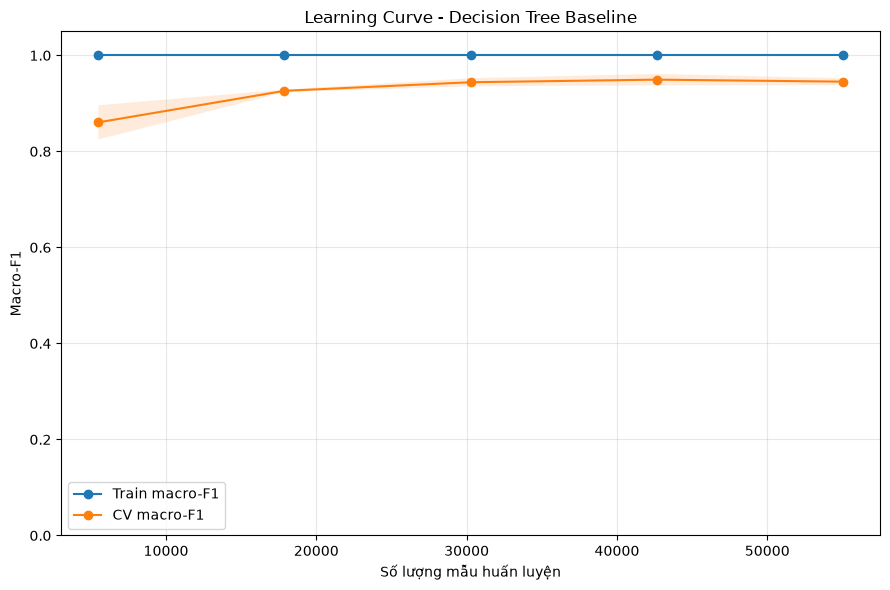

In [13]:
%pip install matplotlib
from sklearn.model_selection import learning_curve

import matplotlib.pyplot as plt

train_sizes, train_scores, valid_scores = learning_curve(
    estimator=base_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring='f1_macro',
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1,
    shuffle=True,
    random_state=RANDOM_STATE,
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
valid_mean = valid_scores.mean(axis=1)
valid_std = valid_scores.std(axis=1)

plt.figure(figsize=(9, 6))
plt.plot(train_sizes, train_mean, 'o-', label='Train macro-F1')
plt.plot(train_sizes, valid_mean, 'o-', label='CV macro-F1')

plt.fill_between(
    train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15
)
plt.fill_between(
    train_sizes, valid_mean - valid_std, valid_mean + valid_std, alpha=0.15
)

plt.title('Learning Curve - Decision Tree Baseline')
plt.xlabel('Số lượng mẫu huấn luyện')
plt.ylabel('Macro-F1')
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    RUN_DIR / 'learning_curve_macro_f1.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()